# EDA 02 — Evolución clínica durante la espera

La **película**: eventos clínicos y mediciones como serie temporal. La pregunta central es si la prioridad inicial anticipa lo que pasa después, o si hay pacientes que empeoran sin que su prioridad cambie.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from carga import cargar, base_paciente, FECHA_REFERENCIA, ORDEN_PRIORIDAD, RANGOS_NORMALES

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
COLOR_PRIO = {"alta": "#c0392b", "media": "#e67e22", "baja": "#2e86c1"}

d = cargar()
pac = base_paciente(d)
lista, eventos, mediciones, agenda, citas = d["lista"], d["eventos"], d["mediciones"], d["agenda"], d["citas"]

In [2]:
ev = eventos.merge(lista[["id_paciente", "especialidad", "prioridad_inicial", "fecha_ingreso_lista"]], on="id_paciente")
ev["dias_desde_ingreso"] = (ev["fecha_evento"] - ev["fecha_ingreso_lista"]).dt.days
me = mediciones.merge(lista[["id_paciente", "especialidad", "prioridad_inicial", "fecha_ingreso_lista"]], on="id_paciente")
me["dias_desde_ingreso"] = (me["fecha_medicion"] - me["fecha_ingreso_lista"]).dt.days
GRAVE = ev["severidad"] == "grave"
print(f"{len(ev)} eventos en {ev.id_paciente.nunique()} pacientes · {len(me)} mediciones en {me.id_paciente.nunique()} pacientes")

786 eventos en 381 pacientes · 2487 mediciones en 451 pacientes


## 1. Eventos clínicos

In [3]:
(ev.groupby(["tipo_evento", "subtipo", "severidad"], observed=True).size()
   .rename("n").reset_index().sort_values("n", ascending=False).reset_index(drop=True))

,tipo_evento,subtipo,severidad,n
0,control_aps,control de rutina,leve,105
1,control_aps,control crónico,leve,103
2,cambio_farmaco,aumento dosis,moderada,103
3,examen_alterado,resultado alterado,moderada,103
4,visita_urgencia,triage ESI 2,grave,55
5,hospitalizacion,ingreso hospitalario,grave,55
6,control_aps,control,leve,54
7,cambio_farmaco,reducción dosis,leve,49
8,control_aps,buena respuesta,leve,49
9,visita_urgencia,descompensación,moderada,40


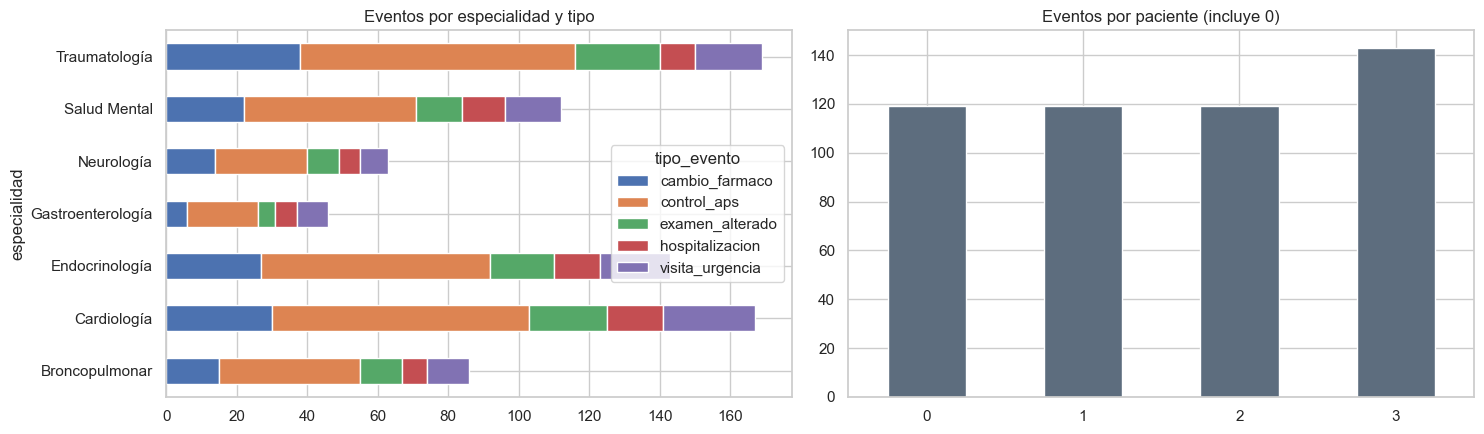

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(ev["especialidad"], ev["tipo_evento"]).plot.barh(stacked=True, ax=ax[0]).set_title("Eventos por especialidad y tipo")
n_ev = ev.groupby("id_paciente").size().reindex(lista["id_paciente"], fill_value=0)
n_ev.value_counts().sort_index().plot.bar(ax=ax[1], rot=0, color="#5d6d7e").set_title("Eventos por paciente (incluye 0)")
plt.tight_layout()

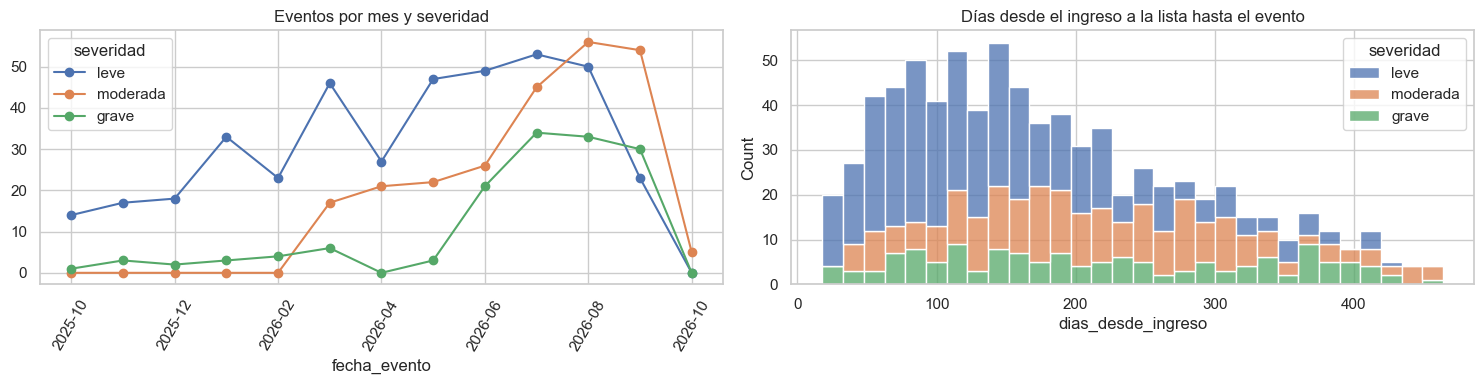

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
pd.crosstab(ev["fecha_evento"].dt.strftime("%Y-%m"), ev["severidad"]).plot(ax=ax[0], marker="o", rot=60)
ax[0].set_title("Eventos por mes y severidad")
sns.histplot(ev, x="dias_desde_ingreso", hue="severidad", multiple="stack", bins=30, ax=ax[1]).set_title("Días desde el ingreso a la lista hasta el evento")
plt.tight_layout()

## 2. ¿La prioridad inicial anticipa la evolución?

Si la foto inicial fuera buena, los pacientes con prioridad **baja** deberían tener pocos eventos graves. Comparamos la tasa de eventos graves por paciente según la prioridad inicial.

In [6]:
por_pac = lista[["id_paciente", "especialidad", "prioridad_inicial", "estado"]].copy()
por_pac["n_eventos"] = por_pac["id_paciente"].map(ev.groupby("id_paciente").size()).fillna(0).astype(int)
por_pac["n_graves"] = por_pac["id_paciente"].map(ev[GRAVE].groupby("id_paciente").size()).fillna(0).astype(int)
por_pac["n_moderados"] = por_pac["id_paciente"].map(ev[ev["severidad"] == "moderada"].groupby("id_paciente").size()).fillna(0).astype(int)
por_pac["con_grave"] = por_pac["n_graves"] > 0
tabla = por_pac.groupby("prioridad_inicial", observed=True).agg(
    pacientes=("id_paciente", "size"),
    con_evento_grave=("con_grave", "sum"),
    pct_con_grave=("con_grave", lambda s: round(s.mean() * 100, 1)),
    eventos_por_paciente=("n_eventos", "mean"),
)
tabla.round(2)

,pacientes,con_evento_grave,pct_con_grave,eventos_por_paciente
prioridad_inicial,,,,
alta,94,15,16.0,1.57
media,238,36,15.1,1.58
baja,168,19,11.3,1.56


In [7]:
from scipy.stats import chi2_contingency
chi2, p, *_ = chi2_contingency(pd.crosstab(por_pac["prioridad_inicial"], por_pac["con_grave"]))
print(f"χ² prioridad inicial vs. tener evento grave: χ²={chi2:.2f}, p={p:.4f}")

χ² prioridad inicial vs. tener evento grave: χ²=1.56, p=0.4584


In [8]:
# Pacientes que empeoran sin que la foto lo refleje: prioridad baja/media, en espera, con evento grave
despertar = por_pac[(por_pac["prioridad_inicial"] != "alta") & por_pac["con_grave"] & (por_pac["estado"] == "en_espera")]
print(f"{len(despertar)} pacientes en espera con prioridad baja/media y al menos un evento grave "
      f"({len(despertar) / (por_pac['estado'] == 'en_espera').sum():.1%} de los en espera)")
despertar.groupby(["especialidad", "prioridad_inicial"], observed=True).size().unstack(fill_value=0)

41 pacientes en espera con prioridad baja/media y al menos un evento grave (10.0% de los en espera)


prioridad_inicial,media,baja
especialidad,,
Broncopulmonar,4,1
Cardiología,6,3
Endocrinología,5,1
Gastroenterología,2,2
Neurología,3,2
Salud Mental,2,3
Traumatología,6,1


count     70.0
mean     208.0
std      114.0
min       22.0
25%      112.0
50%      190.0
75%      312.0
max      405.0
Name: dias_desde_ingreso, dtype: float64

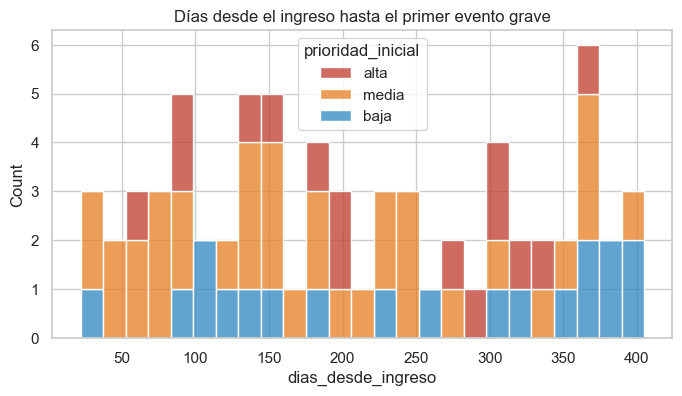

In [9]:
# Primer evento grave: cuánto tarda en aparecer desde el ingreso
primer_grave = ev[GRAVE].sort_values("fecha_evento").groupby("id_paciente").first()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(primer_grave, x="dias_desde_ingreso", hue="prioridad_inicial", hue_order=ORDEN_PRIORIDAD, palette=COLOR_PRIO, multiple="stack", bins=25, ax=ax)
ax.set_title("Días desde el ingreso hasta el primer evento grave")
primer_grave["dias_desde_ingreso"].describe().round(0)

## 3. Secuencias de eventos

¿Las urgencias preceden a las hospitalizaciones? Transiciones entre eventos consecutivos del mismo paciente.

Text(0.5, 11.109374999999995, 'siguiente')

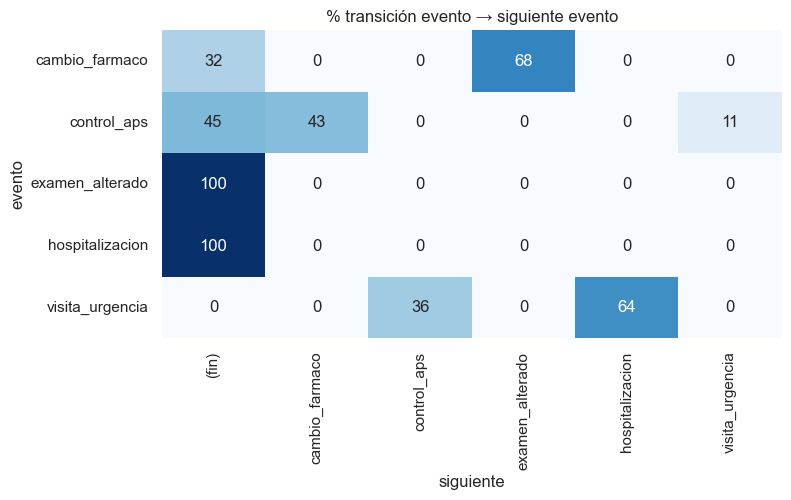

In [10]:
ev_ord = ev.sort_values(["id_paciente", "fecha_evento"])
ev_ord["siguiente"] = ev_ord.groupby("id_paciente")["tipo_evento"].shift(-1)
ev_ord["dias_al_siguiente"] = (ev_ord.groupby("id_paciente")["fecha_evento"].shift(-1) - ev_ord["fecha_evento"]).dt.days
trans = pd.crosstab(ev_ord["tipo_evento"], ev_ord["siguiente"].fillna("(fin)"), normalize="index").mul(100).round(1)
plt.figure(figsize=(8, 4))
sns.heatmap(trans, annot=True, fmt=".0f", cmap="Blues", cbar=False).set_title("% transición evento → siguiente evento")
plt.ylabel("evento"); plt.xlabel("siguiente")

In [11]:
ev_ord[(ev_ord["tipo_evento"] == "visita_urgencia") & (ev_ord["siguiente"] == "hospitalizacion")]["dias_al_siguiente"].describe().round(1)

count     70.0
mean      19.0
std       14.6
min        4.0
25%       10.0
50%       16.5
75%       23.8
max      103.0
Name: dias_al_siguiente, dtype: float64

In [12]:
# A nivel de subtipo, las secuencias son deterministas (artefacto del generador sintético)
ev_ord["subtipo_siguiente"] = ev_ord.groupby("id_paciente")["subtipo"].shift(-1)
urg = ev_ord[ev_ord["tipo_evento"] == "visita_urgencia"]
display(pd.crosstab(urg["subtipo"], urg["subtipo_siguiente"].fillna("(fin)")))
n_graves = ev[GRAVE].groupby("id_paciente").size()
print(f"Pacientes con eventos graves: {len(n_graves)} · eventos graves por paciente: {n_graves.value_counts().to_dict()}")

subtipo_siguiente,estabilización,ingreso UCI,ingreso hospitalario
subtipo,,,
descompensación,40,0,0
descompensación grave,0,15,0
triage ESI 2,0,0,55


Pacientes con eventos graves: 70 · eventos graves por paciente: {2: 70}


## 4. Mediciones

In [13]:
me_res = me.groupby(["especialidad", "tipo_medicion", "unidad"]).agg(
    n=("valor", "size"), pacientes=("id_paciente", "nunique"),
    media=("valor", "mean"), p10=("valor", lambda s: s.quantile(.1)), p90=("valor", lambda s: s.quantile(.9)),
    pct_fuera=("fuera_de_rango", lambda s: round(s.mean() * 100, 1)))
me_res["rango_normal"] = [RANGOS_NORMALES[t] for t in me_res.index.get_level_values("tipo_medicion")]
me_res.round(1)

n  pacientes  media    p10  \
especialidad      tipo_medicion      unidad                                 
Broncopulmonar    peak_flow          L/min   121         44  432.2  307.0   
                  saturacion_o2      %       155         46   97.1   94.0   
Cardiología       presion_diastolica mmHg    255         82   79.9   62.0   
                  presion_sistolica  mmHg    254         77  124.9   94.0   
Endocrinología    HbA1c              %       210         64    7.0    4.5   
                  glicemia           mg/dL   247         71  118.4   74.0   
Gastroenterología glicemia           mg/dL   152         33  117.0   80.5   
Neurología        escala_dolor_eva   puntos  195         35    3.9    0.0   
Salud Mental      PHQ9               puntos  344         70    8.3    0.0   
Traumatología     escala_dolor_eva   puntos  554         97    3.9    0.0   

                                               p90  pct_fuera rango_normal  
especialidad      tipo_medicion      unidad                                 
Broncopulmonar    peak_flow          L/min   550.0       22.3   (350, 600)  
                  saturacion_o2      %       100.0       18.1    (95, 100)  
Cardiología       presion_diastolica mmHg     97.0       29.4     (60, 89)  
                  presion_sistolica  mmHg    156.7       37.0    (90, 139)  
Endocrinología    HbA1c              %         9.2       68.6   (4.0, 6.4)  
                  glicemia           mg/dL   161.4       34.0    (70, 140)  
Gastroenterología glicemia           mg/dL   151.9       25.7    (70, 140)  
Neurología        escala_dolor_eva   puntos    8.0       48.2       (0, 3)  
Salud Mental      PHQ9               puntos   16.0       39.5       (0, 9)  
Traumatología     escala_dolor_eva   puntos    8.0       50.2       (0, 3)

In [14]:
# Verificar que fuera_de_rango coincide con los rangos documentados
def fuera(r):
    lo, hi = RANGOS_NORMALES[r.tipo_medicion]
    return not (lo <= r.valor <= hi)
me["fuera_calc"] = me.apply(fuera, axis=1)
print("Coincidencia fuera_de_rango vs. rangos documentados:", f"{(me['fuera_calc'] == me['fuera_de_rango']).mean():.1%}")
me.loc[me["fuera_calc"] != me["fuera_de_rango"], ["tipo_medicion", "valor", "fuera_de_rango", "fuera_calc"]].head(10)

Coincidencia fuera_de_rango vs. rangos documentados: 100.0%


,tipo_medicion,valor,fuera_de_rango,fuera_calc


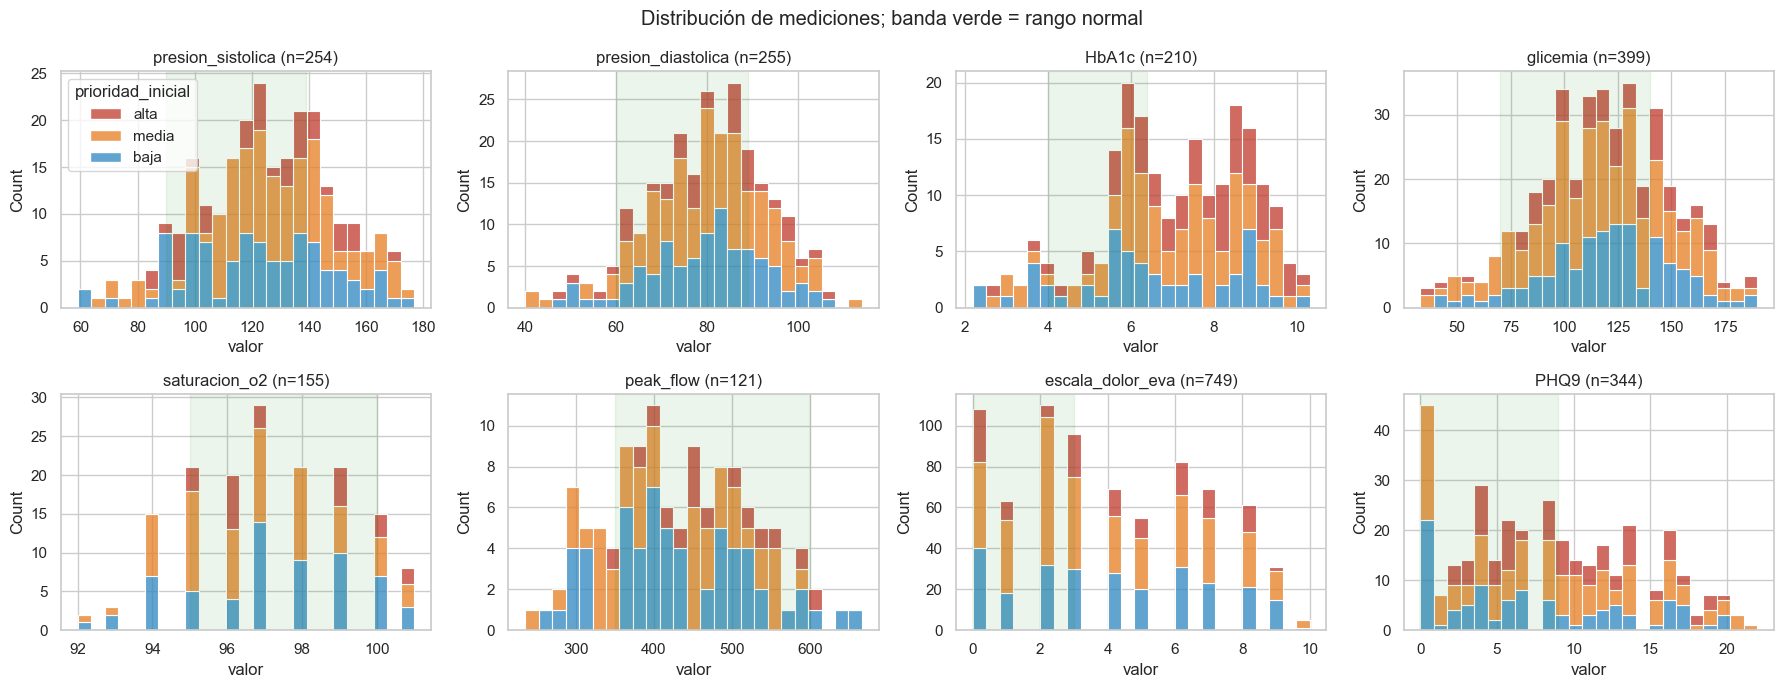

In [15]:
tipos = list(RANGOS_NORMALES)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, t in zip(axes.flat, tipos):
    sub = me[me["tipo_medicion"] == t]
    sns.histplot(sub, x="valor", hue="prioridad_inicial", hue_order=ORDEN_PRIORIDAD, palette=COLOR_PRIO, multiple="stack", bins=25, ax=ax, legend=(t == tipos[0]))
    lo, hi = RANGOS_NORMALES[t]
    ax.axvspan(lo, hi, color="green", alpha=.08)
    ax.set_title(f"{t} (n={len(sub)})")
plt.suptitle("Distribución de mediciones; banda verde = rango normal")
plt.tight_layout()

## 5. Tendencias por paciente

Pendiente de la recta (valor por cada 30 días) en pacientes con ≥ 3 mediciones del mismo tipo. Para saturación y peak flow, bajar es empeorar; para el resto, subir es empeorar. Se normaliza el signo: **pendiente_empeora > 0 = empeora**.

In [16]:
MEJOR_ALTO = {"saturacion_o2", "peak_flow"}

def pendiente(g):
    if len(g) < 3:
        return np.nan
    x = (g["fecha_medicion"] - g["fecha_medicion"].min()).dt.days.values
    if x.max() == 0:
        return np.nan
    return np.polyfit(x, g["valor"].values, 1)[0] * 30

tend = me.groupby(["id_paciente", "especialidad", "prioridad_inicial", "tipo_medicion"], observed=True).apply(pendiente).rename("pendiente_30d").dropna().reset_index()
tend["ancho_rango"] = tend["tipo_medicion"].map(lambda t: RANGOS_NORMALES[t][1] - RANGOS_NORMALES[t][0])
signo = np.where(tend["tipo_medicion"].isin(MEJOR_ALTO), -1, 1)
tend["pendiente_empeora"] = signo * tend["pendiente_30d"] / tend["ancho_rango"]   # en anchos de rango por mes
tend.groupby("tipo_medicion")["pendiente_empeora"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
tipo_medicion,,,,,,,,
HbA1c,35.0,0.164,0.302,-0.228,-0.003,0.106,0.221,1.097
PHQ9,49.0,0.091,0.233,-0.269,-0.056,0.087,0.147,1.240
escala_dolor_eva,101.0,0.179,0.316,-0.464,-0.024,0.089,0.320,1.131
glicemia,62.0,0.046,0.180,-0.514,-0.037,0.047,0.113,0.636
peak_flow,16.0,0.040,0.162,-0.391,0.007,0.047,0.072,0.386
presion_diastolica,42.0,0.039,0.155,-0.453,-0.002,0.056,0.122,0.377
presion_sistolica,43.0,0.049,0.146,-0.479,-0.022,0.062,0.133,0.355
saturacion_o2,25.0,0.066,0.123,-0.124,0.012,0.060,0.083,0.514


Text(0.5, 1.0, 'Tendencia normalizada (anchos de rango por mes; >0 = empeora)')

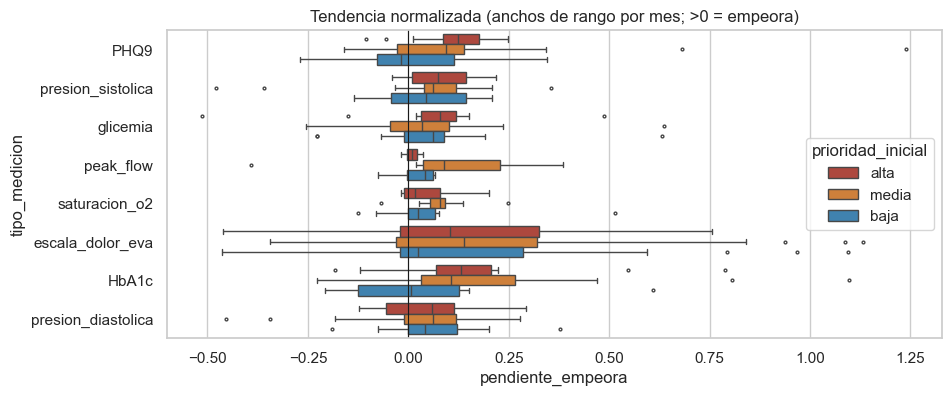

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(tend, x="pendiente_empeora", y="tipo_medicion", hue="prioridad_inicial", hue_order=ORDEN_PRIORIDAD, palette=COLOR_PRIO, ax=ax, fliersize=2)
ax.axvline(0, color="k", lw=.8)
ax.set_title("Tendencia normalizada (anchos de rango por mes; >0 = empeora)")

In [18]:
# ¿Las tendencias de empeoramiento coinciden con eventos graves?
t_pac = tend.groupby("id_paciente")["pendiente_empeora"].max().rename("max_empeora")
cmp = por_pac.set_index("id_paciente").join(t_pac, how="inner")
cmp["tendencia"] = pd.cut(cmp["max_empeora"], [-np.inf, 0, 0.1, np.inf], labels=["mejora/estable", "empeora leve", "empeora fuerte"])
pd.crosstab(cmp["tendencia"], cmp["con_grave"], margins=True, normalize="index").mul(100).round(1).rename(columns={True: "% con evento grave", False: "% sin evento grave"})

con_grave,% sin evento grave,% con evento grave
tendencia,,
mejora/estable,98.9,1.1
empeora leve,80.8,19.2
empeora fuerte,64.4,35.6
All,79.3,20.7


## 6. Señales combinadas: ¿la medición alterada anticipa el evento?

In [19]:
# Para cada primer evento grave, ¿había una medición fuera de rango en los 60 días previos?
pg = primer_grave.reset_index()[["id_paciente", "fecha_evento"]]
m_fr = me[me["fuera_de_rango"]][["id_paciente", "fecha_medicion"]]
x = pg.merge(m_fr, on="id_paciente", how="left")
x["previa"] = (x["fecha_medicion"] < x["fecha_evento"]) & (x["fecha_medicion"] >= x["fecha_evento"] - pd.Timedelta(days=60))
anticipa = x.groupby("id_paciente")["previa"].any()
print(f"Primeros eventos graves con medición fuera de rango en los 60 días previos: {anticipa.mean():.1%} ({anticipa.sum()}/{len(anticipa)})")

# Línea base: pacientes sin evento grave, en una fecha aleatoria
rng = np.random.default_rng(0)
sin = lista[~lista["id_paciente"].isin(pg["id_paciente"]) & lista["id_paciente"].isin(me["id_paciente"])][["id_paciente", "fecha_ingreso_lista"]].copy()
sin["fecha_evento"] = sin["fecha_ingreso_lista"] + pd.to_timedelta(rng.integers(60, 300, len(sin)), unit="D")
y = sin.merge(m_fr, on="id_paciente", how="left")
y["previa"] = (y["fecha_medicion"] < y["fecha_evento"]) & (y["fecha_medicion"] >= y["fecha_evento"] - pd.Timedelta(days=60))
print(f"Línea base (pacientes sin evento grave, fecha al azar): {y.groupby('id_paciente')['previa'].any().mean():.1%}")

Primeros eventos graves con medición fuera de rango en los 60 días previos: 32.9% (23/70)
Línea base (pacientes sin evento grave, fecha al azar): 23.1%


## 7. Líneas de tiempo de los casos de referencia (`docs/casos-ejemplo.md`)

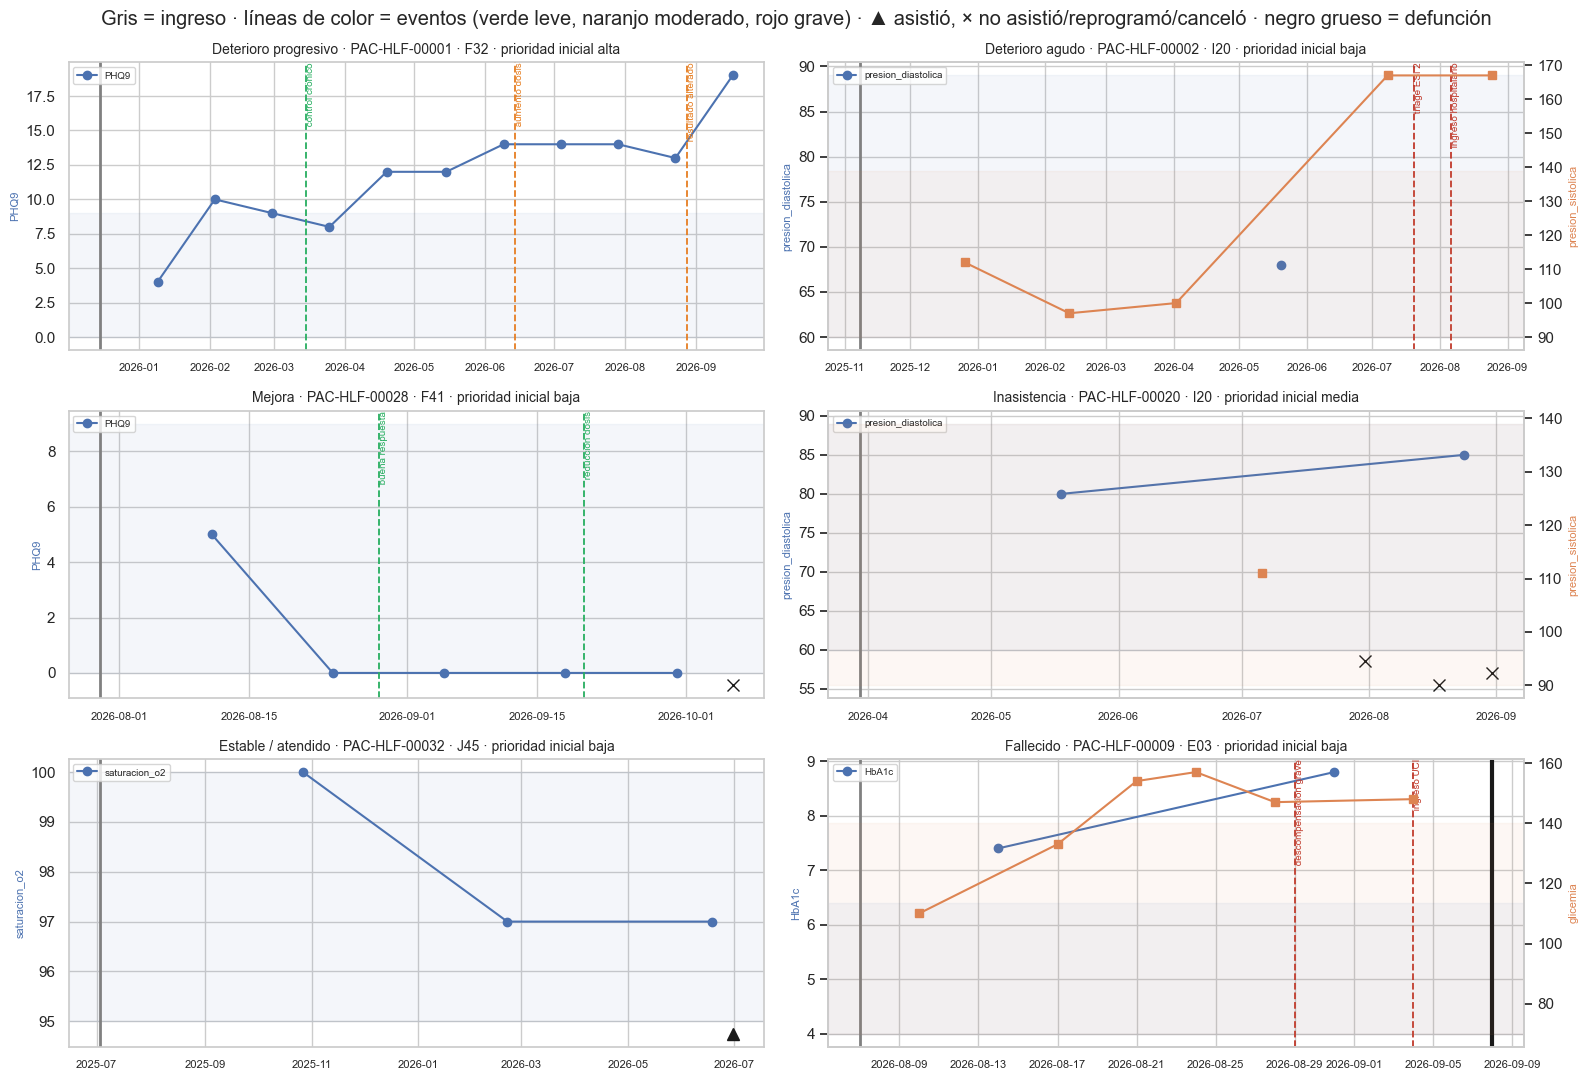

In [20]:
CASOS = {"PAC-HLF-00001": "Deterioro progresivo", "PAC-HLF-00002": "Deterioro agudo", "PAC-HLF-00028": "Mejora",
         "PAC-HLF-00020": "Inasistencia", "PAC-HLF-00032": "Estable / atendido", "PAC-HLF-00009": "Fallecido"}
COLOR_SEV = {"leve": "#27ae60", "moderada": "#e67e22", "grave": "#c0392b"}
fig, axes = plt.subplots(3, 2, figsize=(16, 11))
for ax, (pid, patron) in zip(axes.flat, CASOS.items()):
    p = pac.set_index("id_paciente").loc[pid]
    m = me[me["id_paciente"] == pid]
    for j, (t, g) in enumerate(m.groupby("tipo_medicion")):
        # Segundo tipo de medición en eje derecho (unidades distintas)
        a = ax if j == 0 else ax.twinx()
        a.plot(g["fecha_medicion"], g["valor"], marker="o" if j == 0 else "s", color=f"C{j}", label=t)
        lo, hi = RANGOS_NORMALES[t]
        a.axhspan(lo, hi, color=f"C{j}", alpha=.06)
        a.set_ylabel(t, color=f"C{j}", fontsize=8)
        a.grid(False) if j else None
    for _, e in ev[ev["id_paciente"] == pid].iterrows():
        ax.axvline(e["fecha_evento"], color=COLOR_SEV[e["severidad"]], ls="--", lw=1.3)
        ax.text(e["fecha_evento"], ax.get_ylim()[1], " " + e["subtipo"], rotation=90, va="top", fontsize=7, color=COLOR_SEV[e["severidad"]])
    for _, c in citas[citas["id_paciente"] == pid].iterrows():
        ax.plot(c["fecha_cita"], ax.get_ylim()[0], marker="^" if c["estado_cita"] == "asistio" else "x", color="k", ms=9, clip_on=False)
    ax.axvline(p["fecha_ingreso_lista"], color="grey", lw=2)
    if pd.notna(p["fecha_defuncion"]):
        ax.axvline(p["fecha_defuncion"], color="k", lw=3)
    ax.set_title(f"{patron} · {pid} · {p['diagnostico_cie10']} · prioridad inicial {p['prioridad_inicial']}", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(axis="x", labelsize=8)
plt.suptitle("Gris = ingreso · líneas de color = eventos (verde leve, naranjo moderado, rojo grave) · ▲ asistió, × no asistió/reprogramó/canceló · negro grueso = defunción")
plt.tight_layout()

## Hallazgos

1. **La foto no predice la película.** El porcentaje de pacientes con al menos un evento grave es similar en prioridad alta (16 %), media (15 %) y baja (11 %); χ² p = 0,46. La prioridad inicial no anticipa quién se descompensará.
2. **41 pacientes en espera (10 %) tienen prioridad baja o media y al menos un evento grave.** Son el grupo objetivo del reto: la lista actual no los reconoce.
3. **La tendencia de las mediciones es la mejor señal temprana.** Entre los pacientes con ≥ 3 mediciones, quienes tienen una tendencia fuerte al empeoramiento tienen evento grave en el 36 % de los casos; quienes mejoran o están estables, en el 1 %. Una medición fuera de rango aislada en los 60 días previos anticipa poco (33 % vs. 23 % de línea base).
4. **Secuencias deterministas (artefacto sintético).** Toda urgencia grave termina en hospitalización, con una mediana de 16,5 días: triage ESI 2 → ingreso hospitalario y descompensación grave → ingreso UCI. Además, toda descompensación moderada → estabilización. Cada uno de los 70 pacientes con eventos graves tiene exactamente un episodio. **No sobreajustar reglas a estas secuencias**: en datos reales no serán tan limpias.
5. **El primer evento grave llega tarde:** mediana de 190 días desde el ingreso. Hay tiempo para detectar el deterioro con mediciones antes de la urgencia.
6. **`fuera_de_rango` coincide al 100 % con los rangos documentados.** HbA1c es la medición más alterada (69 % fuera de rango), seguida de la EVA (≈ 50 %).
